In [1]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
import io
import torch
import torchvision
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import Dataset, DataLoader

In [2]:
# Set the seed for reproducibility
torch.manual_seed(42)

In [3]:
# Check if GPU is available, else use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
# Define the transforms to apply to the data
train_transforms = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.Grayscale(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

test_transforms = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.Grayscale(),
    transforms.ToTensor()
])

In [5]:
# Load the dataset and create a dataloader
dataset = datasets.ImageFolder("../input/brain-mri-images-for-brain-tumor-detection/brain_tumor_dataset", train_transforms)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

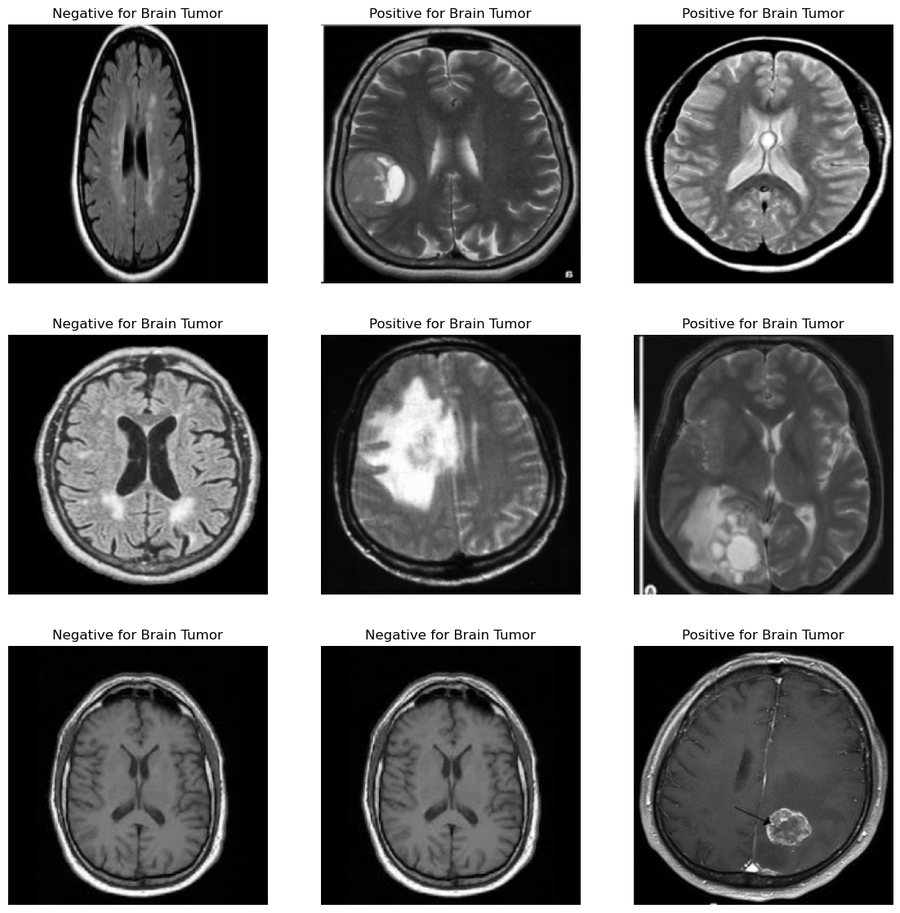

In [6]:
dataiter = iter(dataloader)
X,Y = next(dataiter)
classes = {0: 'Negative for Brain Tumor', 1: 'Positive for Brain Tumor'}
fig,axes = plt.subplots(3,3,figsize=(14,14))
for i in range(3):
    for j in range(3):
        plt.sca(axes[i,j])
        idx = np.random.randint(0,31)
        image = np.moveaxis(X[idx].numpy(),0,2)
        plt.title(classes[Y[idx].item()])
        plt.imshow(image,cmap='gray')
        plt.axis('off');

In [7]:
# Define the CNN architecture
def convBlock(ni, no):
    return nn.Sequential(
        nn.Conv2d(ni, no, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.BatchNorm2d(no),
        nn.Conv2d(no, no, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.BatchNorm2d(no),
        nn.MaxPool2d(2),
    )

In [8]:
class BrainCancerClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = convBlock(1, 32)
        self.conv2 = convBlock(32, 64)
        self.conv3 = convBlock(64, 128)
        self.conv4 = convBlock(128, 256)
        self.conv5 = convBlock(256, 512)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(512, 256)
        self.relu = nn.ReLU(inplace=True)
        self.fc2 = nn.Linear(256, 2)
    
    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [9]:
# Create an instance of the model and move it to the device
model = BrainCancerClassifier().to(device)

In [10]:
# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [12]:
# Train The Model 
num_epochs = 20
for epoch in range(num_epochs):
    total_loss = 0
    total_correct = 0
    total_samples = 0
    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_correct += (predicted == labels).sum().item()
        total_samples += labels.size(0)
    accuracy = total_correct / total_samples
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {total_loss/len(dataloader):.4f}, Accuracy: {accuracy:.4f}")

Epoch [1/20], Loss: 0.4795, Accuracy: 0.7787
Epoch [2/20], Loss: 0.4683, Accuracy: 0.8063
Epoch [3/20], Loss: 0.4495, Accuracy: 0.8379
Epoch [6/20], Loss: 0.3519, Accuracy: 0.8538
Epoch [7/20], Loss: 0.3713, Accuracy: 0.8261
Epoch [8/20], Loss: 0.3388, Accuracy: 0.8498
Epoch [9/20], Loss: 0.3148, Accuracy: 0.8735
Epoch [10/20], Loss: 0.3081, Accuracy: 0.8775
Epoch [11/20], Loss: 0.3573, Accuracy: 0.8656
Epoch [12/20], Loss: 0.2802, Accuracy: 0.9012
Epoch [13/20], Loss: 0.2529, Accuracy: 0.8814
Epoch [14/20], Loss: 0.2218, Accuracy: 0.8972
Epoch [15/20], Loss: 0.1918, Accuracy: 0.9289
Epoch [16/20], Loss: 0.1601, Accuracy: 0.9447
Epoch [17/20], Loss: 0.1473, Accuracy: 0.9486
Epoch [18/20], Loss: 0.1853, Accuracy: 0.9209
Epoch [19/20], Loss: 0.1251, Accuracy: 0.9565
Epoch [20/20], Loss: 0.1207, Accuracy: 0.9526


In [13]:
# Save the trained model
torch.save(model.state_dict(), "brain_cancer_classifier.pth")

In [14]:
def predict_and_draw(image_bytes):
    # Load the image bytes into a numpy array
    image_np = np.frombuffer(image_bytes, dtype=np.uint8)
    image = cv2.imdecode(image_np, flags=cv2.IMREAD_COLOR)
    
    # Resize and convert the image to grayscale
    image = cv2.resize(image, (256, 256))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    # Normalize the image
    image = image / 255.0
    
    # Convert the image to a PyTorch tensor
    image = torch.tensor(image, dtype=torch.float32)
    image = image.unsqueeze(0).unsqueeze(0)
    
    # Make a prediction using the model
    with torch.no_grad():
        output = model(image)
        predicted = torch.argmax(output, dim=1)
    
    # Convert the PyTorch tensor to a numpy array
    image = image.squeeze().cpu()
    image_np = np.array(image)
    
    # If the model predicts that there is a tumor, draw a square around the tumor area
    if predicted.item() == 1:
        # Find the contours of the tumor area
        contours, _ = cv2.findContours(np.uint8(image_np*255), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        # Draw a square around the tumor area
        x,y,w,h = cv2.boundingRect(contours[0])
        image_with_square = cv2.rectangle(image_np, (x,y), (x+w,y+h), (0, 255, 0), 2)
    else:
        image_with_square = image_np

    # Convert the image to a color image for drawing the square
    image_with_square = cv2.cvtColor(image_with_square, cv2.COLOR_GRAY2BGR)

    # If the model predicts that there is a tumor, draw a square around the tumor area
    if predicted.item() == 1:
        # Find the contours of the tumor area
        contours, _ = cv2.findContours(np.uint8(image_np*255), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        # Draw a square around the tumor area
        x,y,w,h = cv2.boundingRect(contours[0])
        image_with_square = cv2.rectangle(image_with_square, (x,y), (x+w,y+h), (0, 255, 0), 2)

    # Return the predicted class and the image with the square drawn around the tumor area
    return ("Tumor" if predicted.item() == 1 else "No Tumor", image_with_square)

Predicted Class: Tumor


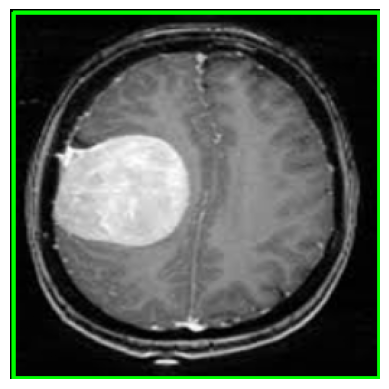

In [15]:
# Test the function on an example image
with open("../input/brain-mri-images-for-brain-tumor-detection/brain_tumor_dataset/yes/Y1.jpg", "rb") as f:
    image_bytes = f.read()
    predicted_class, image_with_square = predict_and_draw(image_bytes)
    print("Predicted Class:", predicted_class)
    plt.imshow(image_with_square, cmap='gray')
    plt.axis('off')
    plt.show()